# 10 · Capstone: an end-to-end digital twin of a contaminated tank
**Level: Expert** · ~30 min · *Track: Integration*

This notebook runs a complete twin life cycle on the stirred tank of notebooks 05-06:

| Phase | Question | Tool (notebook) |
|---|---|---|
| **0. Commission** | is the twin calibrated? | parameters learned by the EnKF (06) |
| **1. Monitor** | what is the field right now, and how sure are we? | localized EnKF (06) |
| **2. Detect** | is reality doing something the twin doesn't know about? | innovation consistency, NIS (04) |
| **3. Diagnose** | where and how strong is the anomaly? | linear Green's functions + Bayesian grid search (03) |
| **4. Predict** | what happens next under each possible action? | ensemble what-if forecasts |
| **5. Decide & verify** | which action, and did it work? | risk metrics, then closed-loop tracking |

**Story.** A treatment tank is stirred by a pump. A known inlet feeds contaminant at the lower
left and a treatment process removes it at rate λ. A drinking-water **intake** sits on the top
wall. At some unknown time, a crack opens somewhere in the tank and starts leaking. The twin
watches 25 probes.

In [1]:
import sys; sys.path.insert(0, "..")
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2
from IPython.display import HTML, Markdown, display
from dtwin import viz
from dtwin.solvers import AdvDiff2D, gaussian_blob, smooth_noise
from dtwin.sensors import PointSensors, grid_2d, flat_to_xy
from dtwin.assimilation import EnKF
viz.set_style()
rng = np.random.default_rng(2024)

## 0. Reality, the twin, and the plant layout
Reality and twin share the physics but **not exactly the parameters**: the twin uses the values
calibrated in notebook 06 (κ and pump strength a few percent off), which is realistic model error.
Neither the leak's location, strength nor onset time is known to the twin.

dt = 0.0181, 55 steps/cycle; intake baseline 0.087 -> safety limit 0.175


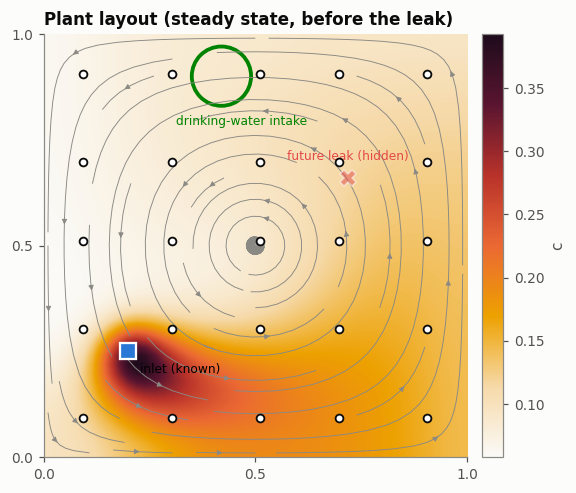

In [2]:
N_GRID, T_OBS, SIGMA = 48, 1.0, 0.005
common = dict(n=N_GRID, decay=0.03, kappa_max=3e-3, flow_max=0.05)
reality = AdvDiff2D(kappa=1.5e-3, flow_amplitude=0.025, **common)
twin = AdvDiff2D(kappa=1.6e-3, flow_amplitude=0.026, **common)
twin.dt = reality.dt
SPC = int(round(T_OBS / reality.dt))            # solver steps per observation cycle
X, Y = reality.X, reality.Y
n_state = N_GRID**2

INLET = gaussian_blob(X, Y, 0.2, 0.25, width=0.04, amp=0.4)
LEAK_XY, LEAK_Q, T_LEAK = (0.72, 0.66), 0.6, 25.0     # hidden from the twin
leak_shape = lambda x0, y0: gaussian_blob(X, Y, x0, y0, width=0.03, amp=1.0)
TRUE_LEAK = LEAK_Q * leak_shape(*LEAK_XY)

INTAKE_XY, INTAKE_R = (0.42, 0.9), 0.07
intake_mask = (np.hypot(X - INTAKE_XY[0], Y - INTAKE_XY[1]) < INTAKE_R)
intake = lambda C: C[..., intake_mask].mean(-1)

obs_idx, _ = grid_2d(N_GRID, 5, margin=0.08)
sens = PointSensors(obs_idx, n_state, SIGMA)
sx, sy = flat_to_xy(obs_idx, N_GRID, reality.x)

# spin up a statistically steady tank (inlet only)
c_real = np.zeros_like(X)
for _ in range(int(80 / reality.dt)):
    c_real = reality.step(c_real, INLET)
BASELINE = intake(c_real)
LIMIT = round(2.0 * BASELINE, 3)
print(f"dt = {reality.dt:.4f}, {SPC} steps/cycle; intake baseline {BASELINE:.3f} -> safety limit {LIMIT}")

fig, ax = plt.subplots(figsize=(5.8, 5))
viz.field(ax, c_real, label="c", title="Plant layout (steady state, before the leak)")
ax.streamplot(reality.x, reality.x, reality.U, reality.V, color=viz.MUTED, density=0.7, linewidth=0.6, arrowsize=0.7)
viz.sensors_2d(ax, sx, sy, s=26)
ax.plot(0.2, 0.25, "s", color=viz.BLUE, ms=11, mec="white", mew=1.5)
ax.annotate("inlet (known)", (0.2, 0.25), xytext=(8, -14), textcoords="offset points", fontsize=8)
ax.add_patch(plt.Circle(INTAKE_XY, INTAKE_R, fill=False, color=viz.GREEN, lw=2.5))
ax.annotate("drinking-water intake", INTAKE_XY, xytext=(-30, -32), textcoords="offset points", fontsize=8, color=viz.GREEN)
ax.plot(*LEAK_XY, "X", color=viz.RED, ms=11, mec="white", alpha=0.5)
ax.annotate("future leak (hidden)", LEAK_XY, xytext=(-40, 12), textcoords="offset points", fontsize=8, color=viz.RED)
viz.save(fig, "10_layout.png")
plt.show()

## 1-2. Monitor and detect
The twin runs a 30-member localized EnKF. Before each analysis it computes the **normalised
innovation squared** $\mathrm{NIS}_k = d_k^\top S_k^{-1} d_k$ of the forecast. While the twin's
model is adequate, NIS fluctuates around its usual level. An unmodelled source makes the forecasts
systematically wrong near it, and NIS jumps.

**Alarm rule:** the threshold is the 99.5th percentile of NIS during a commissioning period
($t\in[5, 20]$, known to be leak-free; this absorbs the twin's small calibration error), and an
alarm requires **2 consecutive** exceedances. After an alarm the twin keeps collecting data for
4 more cycles to confirm and then diagnoses.

In [3]:
N_ENS, CONFIRM = 30, 4
filt = EnKF(obs_idx, SIGMA, inflation=1.03, loc_radius=0.2, coords=np.c_[X.ravel(), Y.ravel()])
E = c_real[None] * rng.uniform(0.7, 1.3, (N_ENS, 1, 1)) + smooth_noise((N_ENS, N_GRID, N_GRID), rng, 4, 0.03)

def twin_forecast(E, src, rng, decay=None, noise=2e-3):
    for _ in range(SPC):
        E = twin.step(E, src, decay=decay)
    return E + smooth_noise(E.shape, rng, 3, noise)

log = {"t": [0.0], "truth": [c_real.copy()], "mean": [E.mean(0)], "std": [E.std(0)], "nis": [np.nan], "y": [None]}
threshold, alarm_k, k = None, None, 0
t0 = time.time()
while True:
    k += 1
    t = k * T_OBS
    for j in range(SPC):                                    # reality evolves, leak may switch on
        tt = t - T_OBS + j * reality.dt
        c_real = reality.step(c_real, INLET + (TRUE_LEAK if tt >= T_LEAK else 0))
    y = sens.observe(c_real, rng)
    E = twin_forecast(E, INLET, rng)
    Ef = E.reshape(N_ENS, -1)
    nis = EnKF.nis(Ef, y, obs_idx, SIGMA)
    E = filt.analysis(Ef, y, rng).reshape(N_ENS, N_GRID, N_GRID)
    for key, val in [("t", t), ("truth", c_real.copy()), ("mean", E.mean(0)), ("std", E.std(0)), ("nis", nis), ("y", y)]:
        log[key].append(val)
    if t == 20:
        threshold = np.percentile(log["nis"][5:21], 99.5)
    if threshold and alarm_k is None and k >= 22 and log["nis"][-1] > threshold and log["nis"][-2] > threshold:
        alarm_k = k
    if alarm_k is not None and k == alarm_k + CONFIRM:
        break
    if k > 80:
        raise RuntimeError("no alarm: the leak went undetected")
k_d = k
print(f"monitoring {time.time()-t0:.0f}s | threshold {threshold:.1f} | leak at t={T_LEAK:.0f}, "
      f"ALARM at t={alarm_k*T_OBS:.0f} (delay {alarm_k*T_OBS-T_LEAK:.0f}), diagnosis at t={k_d*T_OBS:.0f}")

monitoring 2s | threshold 39.3 | leak at t=25, ALARM at t=27 (delay 2), diagnosis at t=31


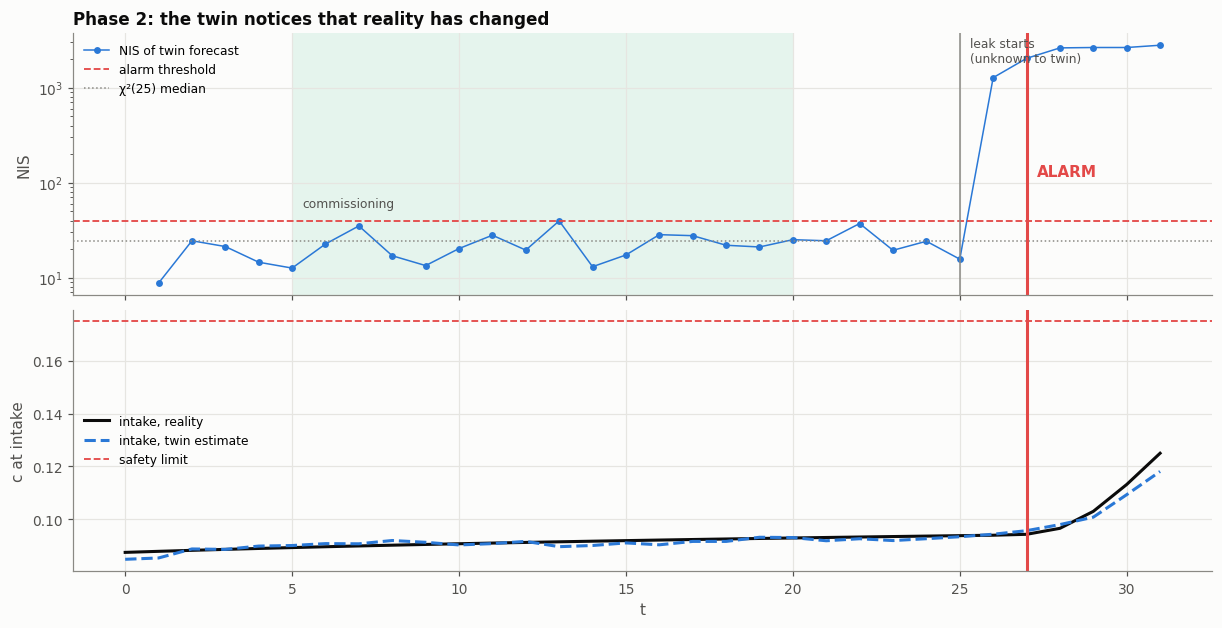

In [4]:
tl = np.array(log["t"])
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), constrained_layout=True, sharex=True)
ax = axes[0]
ax.semilogy(tl, log["nis"], "o-", ms=3.5, lw=1, color=viz.TWIN, label="NIS of twin forecast")
ax.axhline(threshold, color=viz.RED, ls="--", lw=1.2, label="alarm threshold")
ax.axhline(chi2.ppf(0.5, sens.m), color=viz.MUTED, ls=":", lw=1, label="χ²(25) median")
ax.axvspan(5, 20, color=viz.AQUA, alpha=0.1, lw=0)
ax.text(5.3, threshold * 1.4, "commissioning", fontsize=8, color=viz.INK2)
ax.axvline(T_LEAK, color=viz.MUTED, lw=1)
ax.text(T_LEAK + 0.3, ax.get_ylim()[1] * 0.5, "leak starts\n(unknown to twin)", fontsize=8, color=viz.INK2)
ax.axvline(alarm_k * T_OBS, color=viz.RED, lw=2)
ax.text(alarm_k * T_OBS + 0.3, threshold * 3, "ALARM", color=viz.RED, fontweight="bold")
ax.set(ylabel="NIS", title="Phase 2: the twin notices that reality has changed")
ax.legend(loc="upper left", fontsize=8)
ax = axes[1]
truth_int = intake(np.array(log["truth"]))
twin_int = intake(np.array(log["mean"]))
ax.plot(tl, truth_int, color=viz.TRUTH, label="intake, reality")
ax.plot(tl, twin_int, "--", color=viz.TWIN, label="intake, twin estimate")
ax.axhline(LIMIT, color=viz.RED, ls="--", lw=1.2, label="safety limit")
ax.axvline(alarm_k * T_OBS, color=viz.RED, lw=2)
ax.set(xlabel="t", ylabel="c at intake")
ax.legend(fontsize=8)
plt.show()

The alarm comes **before** the intake is affected: the probes near the leak see the plume first,
and the twin knows the plume is not explained by its model.

## 3. Diagnose: where is the leak, how strong, since when?
The transport model is **linear** in $c$. So over a window of $W$ cycles the sensor readings are
$$y_k \approx \underbrace{h_k^{\text{base}}}_{\text{twin without leak}} + q\; g_k(x_0, y_0, \tau)$$
where $g$ is the sensor response to a **unit leak** at $(x_0,y_0)$ switched on at time $\tau$. We
compute $g$ for a 15×15 grid of candidate locations in one batched simulation, and get each
onset time by shifting in time (the system is time-invariant). For every candidate the best $q\ge0$
is a 1D least-squares fit, and the profile likelihood $\propto \mathrm{SSE}^{-n/2}$ gives a
posterior over location and onset.

**Tempering (expert detail):** the residuals are dominated by *model error*, which is strongly
correlated in time, not by independent sensor noise. Treating all $W\times m$ residuals as
independent would give an absurdly confident, one-pixel posterior. We count each probe's time
series as one effective observation ($n_\text{eff}=m$), which is a common, honest correction.

In [5]:
W = 14
k0 = k_d - W                                           # window: cycles k0+1 .. k_d
base = log["mean"][k0].copy()
H_base = []
for _ in range(W):
    for _ in range(SPC):
        base = twin.step(base, INLET)
    H_base.append(sens.observe(base))
H_base = np.array(H_base)                              # (W, m)
Y_win = np.array(log["y"][k0 + 1:k_d + 1])
resid = Y_win - H_base

cand = np.linspace(0.1, 0.9, 15)
CX, CY = np.meshgrid(cand, cand)
cx, cy = CX.ravel(), CY.ravel()
t0 = time.time()
src = np.array([leak_shape(a, b) for a, b in zip(cx, cy)])      # (225, n, n) unit leaks
G = np.zeros((len(cx), N_GRID, N_GRID))
Gs = []
for _ in range(W):
    for _ in range(SPC):
        G = twin.step(G, src)
    Gs.append(sens.observe(G))
Gs = np.array(Gs).transpose(1, 0, 2)                  # (225, W, m) response to leak on at k0
logL = np.full((len(cx), W), -np.inf)
qhat, GG, SSE = (np.zeros((len(cx), W)) for _ in range(3))
n_obs = resid.size
n_eff = sens.m                                        # tempered: one effective obs per probe
for s in range(W):                                    # leak switched on s cycles into the window
    g = np.zeros_like(Gs)
    g[:, s:] = Gs[:, :W - s]
    gg = (g**2).sum((1, 2)) + 1e-12
    q = np.clip((g * resid[None]).sum((1, 2)) / gg, 0, None)
    sse = ((resid[None] - q[:, None, None] * g) ** 2).sum((1, 2))
    logL[:, s] = -0.5 * n_eff * np.log(sse)
    qhat[:, s], GG[:, s], SSE[:, s] = q, gg, sse
post = np.exp(logL - logL.max())
post /= post.sum()
p_loc = post.sum(1)
p_onset = post.sum(0)
j_best, s_best = np.unravel_index(np.argmax(post), post.shape)
loc_hat = (cx[j_best], cy[j_best])
onset_hat = (k0 + s_best) * T_OBS
q_hat = qhat[j_best, s_best]
# least-squares error of q (tempered like the likelihood) + spread across plausible (location, onset)
q_fit_sd = np.sqrt(SSE[j_best, s_best] / n_eff / GG[j_best, s_best])
q_sd = np.hypot(q_fit_sd, np.sqrt((post * (qhat - (post * qhat).sum()) ** 2).sum()))
log_p_loc = np.log10(np.maximum(p_loc, 1e-12)).reshape(15, 15)
print(f"diagnosis in {time.time()-t0:.1f}s")
display(Markdown(f"""| | estimate | truth |
|---|---|---|
| leak location | ({loc_hat[0]:.2f}, {loc_hat[1]:.2f}) | ({LEAK_XY[0]}, {LEAK_XY[1]}) |
| leak strength q | {q_hat:.3f} ± {q_sd:.3f} | {LEAK_Q} |
| onset time | {onset_hat:.0f} | {T_LEAK:.0f} |"""))

diagnosis in 5.9s


| | estimate | truth |
|---|---|---|
| leak location | (0.73, 0.67) | (0.72, 0.66) |
| leak strength q | 0.618 ± 0.017 | 0.6 |
| onset time | 25 | 25 |

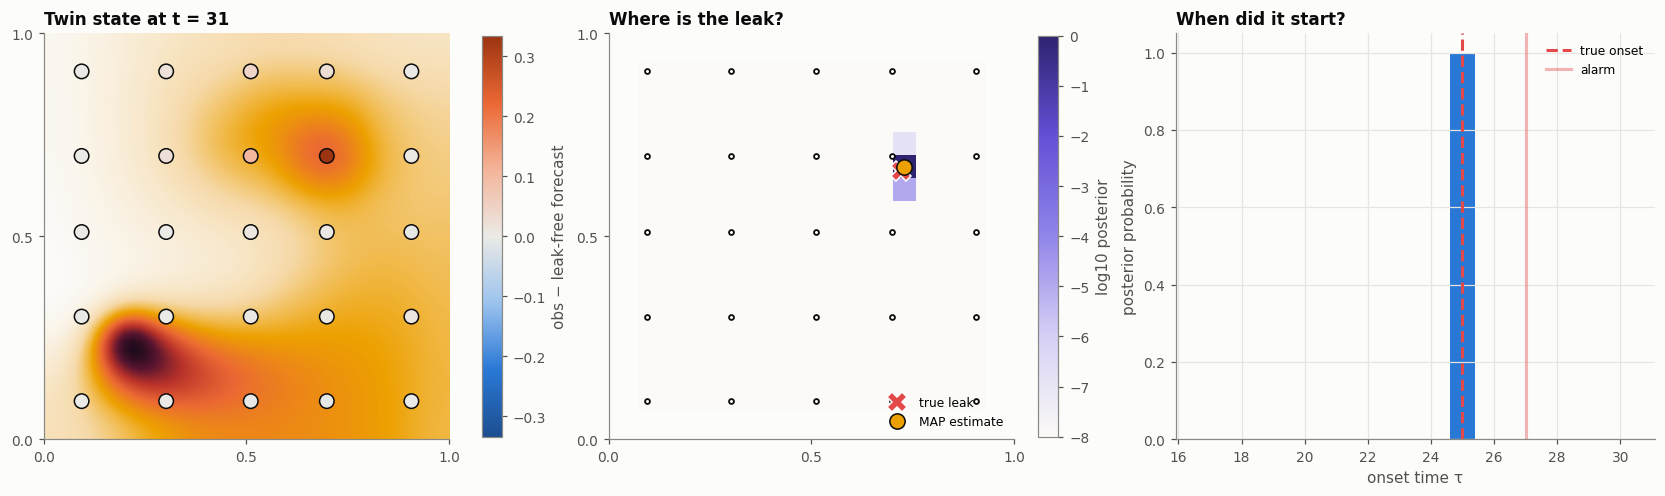

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1, 1.1]})
ax = axes[0]
iv = resid[-1]
lim = np.abs(iv).max()
viz.field(ax, log["mean"][k_d], cmap=viz.FIELD, cbar=False, title=f"Twin state at t = {k_d}")
sc = ax.scatter(sx, sy, c=iv, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, s=90, edgecolor=viz.INK, zorder=5)
plt.colorbar(sc, ax=ax, label="obs − leak-free forecast", fraction=0.046)
ax = axes[1]
viz.field(ax, log_p_loc, cmap=viz.UNCERTAINTY, vmin=-8, vmax=0, label="log10 posterior", title="Where is the leak?")
ax.images[0].set_extent([0.1 - 0.0286, 0.9 + 0.0286, 0.1 - 0.0286, 0.9 + 0.0286])
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.images[0].set_interpolation("nearest")
ax.plot(*LEAK_XY, "X", color=viz.RED, ms=13, mec="white", label="true leak")
ax.plot(*loc_hat, "o", color=viz.YELLOW, ms=10, mec=viz.INK, label="MAP estimate")
viz.sensors_2d(ax, sx, sy, s=10)
ax.legend(loc="lower right", fontsize=8)
ax = axes[2]
ax.bar((k0 + np.arange(W)) * T_OBS, p_onset, width=0.8, color=viz.TWIN)
ax.axvline(T_LEAK, color=viz.RED, ls="--", label="true onset")
ax.axvline(alarm_k * T_OBS, color=viz.RED, lw=2, alpha=0.4, label="alarm")
ax.set(xlabel="onset time τ", ylabel="posterior probability", title="When did it start?")
ax.legend(fontsize=8)
viz.save(fig, "10_diagnosis.png")
plt.show()

## 4. Predict: what-if scenarios with uncertainty
The twin now **adds the diagnosed leak to its own model**, sampling each ensemble member's leak
location from the posterior and its strength from $q \sim \mathcal N(\hat q, \sigma_q)$, so
diagnosis uncertainty flows into the forecast. Four candidate actions, each starting now:

| Action | Model change |
|---|---|
| A. do nothing | leak continues |
| B. isolate leak | leak stops after a 6-unit repair delay |
| C. boost treatment | removal rate λ: 0.03 → 0.10 immediately (costly) |
| D. isolate + boost | both |

Each scenario is forecast 40 time units ahead by the 30-member twin, **and** also simulated in
reality (which a real operator could never do), so we can check the twin's forecasts.

In [7]:
H = 40
REPAIR = 6
draw = rng.choice(len(cx), N_ENS, p=p_loc)
q_ens = np.clip(q_hat + max(q_sd, 0.15 * q_hat) * rng.standard_normal(N_ENS), 0, None)
LEAK_ENS = q_ens[:, None, None] * np.array([leak_shape(cx[d], cy[d]) for d in draw])
E_d = E.copy()
scenarios = {"A. do nothing": (False, 0.03), "B. isolate leak": (True, 0.03),
             "C. boost treatment": (False, 0.10), "D. isolate + boost": (True, 0.10)}
fc, real = {}, {}
t0 = time.time()
for name, (isolate, lam) in scenarios.items():
    Ec, cr = E_d.copy(), log["truth"][k_d].copy()
    ens_int, real_int = [intake(Ec)], [intake(cr)]
    for h in range(1, H + 1):
        leak_on = not (isolate and h > REPAIR)
        r_ = np.random.default_rng(h)
        Ec = twin_forecast(Ec, INLET + (LEAK_ENS if leak_on else 0), r_, decay=lam)
        for _ in range(SPC):
            cr = reality.step(cr, INLET + (TRUE_LEAK if leak_on else 0), decay=lam)
        ens_int.append(intake(Ec))
        real_int.append(intake(cr))
    fc[name], real[name] = np.array(ens_int), np.array(real_int)
print(f"4 scenarios x {N_ENS} members x {H} time units in {time.time()-t0:.0f}s")
th = k_d * T_OBS + np.arange(H + 1) * T_OBS

4 scenarios x 30 members x 40 time units in 8s


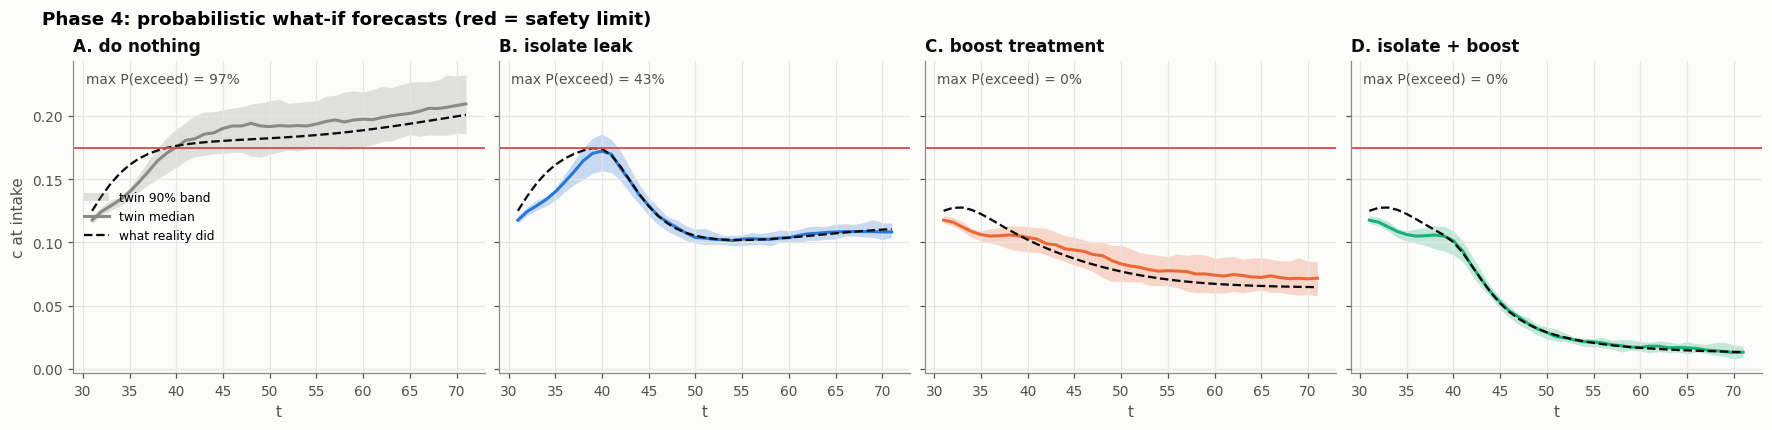

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True, sharey=True)
for ax, (name, F), col in zip(axes, fc.items(), [viz.MUTED, viz.BLUE, viz.ORANGE, viz.AQUA]):
    lo, mid, hi = np.percentile(F, [5, 50, 95], axis=1)
    ax.fill_between(th, lo, hi, color=col, alpha=0.25, lw=0, label="twin 90% band")
    ax.plot(th, mid, color=col, label="twin median")
    ax.plot(th, real[name], color=viz.TRUTH, lw=1.5, ls="--", label="what reality did")
    ax.axhline(LIMIT, color=viz.RED, lw=1.2)
    p_exc = (F > LIMIT).mean(1)
    ax.set(title=name, xlabel="t")
    ax.text(0.03, 0.93, f"max P(exceed) = {p_exc.max():.0%}", transform=ax.transAxes, fontsize=9, color=viz.INK2)
axes[0].set_ylabel("c at intake")
axes[0].legend(loc="center left", fontsize=8)
fig.suptitle("Phase 4: probabilistic what-if forecasts (red = safety limit)", x=0.02, ha="left", fontweight="semibold")
viz.save(fig, "10_scenarios.png")
plt.show()

## 5. Decide: a risk table
A simple decision rule: pick the **cheapest action whose probability of exceeding the limit
stays below 10%** at all times. Costs are illustrative units.

In [9]:
costs = {"A. do nothing": 0, "B. isolate leak": 3, "C. boost treatment": 5, "D. isolate + boost": 8}
rows, ok = [], []
for name, F in fc.items():
    p_exc = (F > LIMIT).mean(1)
    exp_time = p_exc.sum() * T_OBS
    real_time = (real[name] > LIMIT).sum() * T_OBS
    safe = p_exc.max() < 0.10
    ok.append((costs[name], name) if safe else (np.inf, name))
    rows.append(f"| {name} | {costs[name]} | {p_exc.max():.0%} | {exp_time:.1f} | {real_time:.0f} | {'✅' if safe else '❌'} |")
choice = min(ok)[1]
display(Markdown("| action | cost | max P(exceed) | expected time above limit | actual time above limit | acceptable |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(rows) + f"\n\n**Recommended action: {choice}**"))

| action | cost | max P(exceed) | expected time above limit | actual time above limit | acceptable |
|---|---|---|---|---|---|
| A. do nothing | 0 | 97% | 29.5 | 32 | ❌ |
| B. isolate leak | 3 | 43% | 1.2 | 0 | ❌ |
| C. boost treatment | 5 | 0% | 0.0 | 0 | ✅ |
| D. isolate + boost | 8 | 0% | 0.0 | 0 | ✅ |

**Recommended action: C. boost treatment**

## 5b. Verify: closed loop after the decision
Reality executes the recommended action. The twin keeps assimilating, now with the leak in its
model (and switched off after the repair delay if the action isolates it). Does it stay in sync?

In [10]:
isolate, lam = scenarios[choice]
c_r, Ec = log["truth"][k_d].copy(), E_d.copy()
post_log = {"t": [], "truth": [], "mean": [], "std": [], "nis": []}
for h in range(1, H + 1):
    leak_on = not (isolate and h > REPAIR)
    for _ in range(SPC):
        c_r = reality.step(c_r, INLET + (TRUE_LEAK if leak_on else 0), decay=lam)
    y = sens.observe(c_r, rng)
    Ec = twin_forecast(Ec, INLET + (LEAK_ENS if leak_on else 0), rng, decay=lam)
    Ef = Ec.reshape(N_ENS, -1)
    post_log["nis"].append(EnKF.nis(Ef, y, obs_idx, SIGMA))
    Ec = filt.analysis(Ef, y, rng).reshape(N_ENS, N_GRID, N_GRID)
    for key, val in [("t", (k_d + h) * T_OBS), ("truth", c_r.copy()), ("mean", Ec.mean(0)), ("std", Ec.std(0))]:
        post_log[key].append(val)

T_all = np.r_[tl, post_log["t"]]
TR = np.concatenate([np.array(log["truth"]), np.array(post_log["truth"])])
MN = np.concatenate([np.array(log["mean"]), np.array(post_log["mean"])])
SD = np.concatenate([np.array(log["std"]), np.array(post_log["std"])])
NIS_all = np.r_[log["nis"], post_log["nis"]]
rmse = np.sqrt(((MN - TR) ** 2).mean((1, 2)))
print(f"post-decision mean NIS {np.mean(post_log['nis']):.1f} (threshold {threshold:.1f}); "
      f"field RMSE before leak {rmse[5:25].mean():.4f}, after decision {rmse[-20:].mean():.4f}")

post-decision mean NIS 31.6 (threshold 39.3); field RMSE before leak 0.0022, after decision 0.0057


## 6. The operator dashboard
Everything the twin knows at a glance: live field, uncertainty, diagnosis, health and risk.

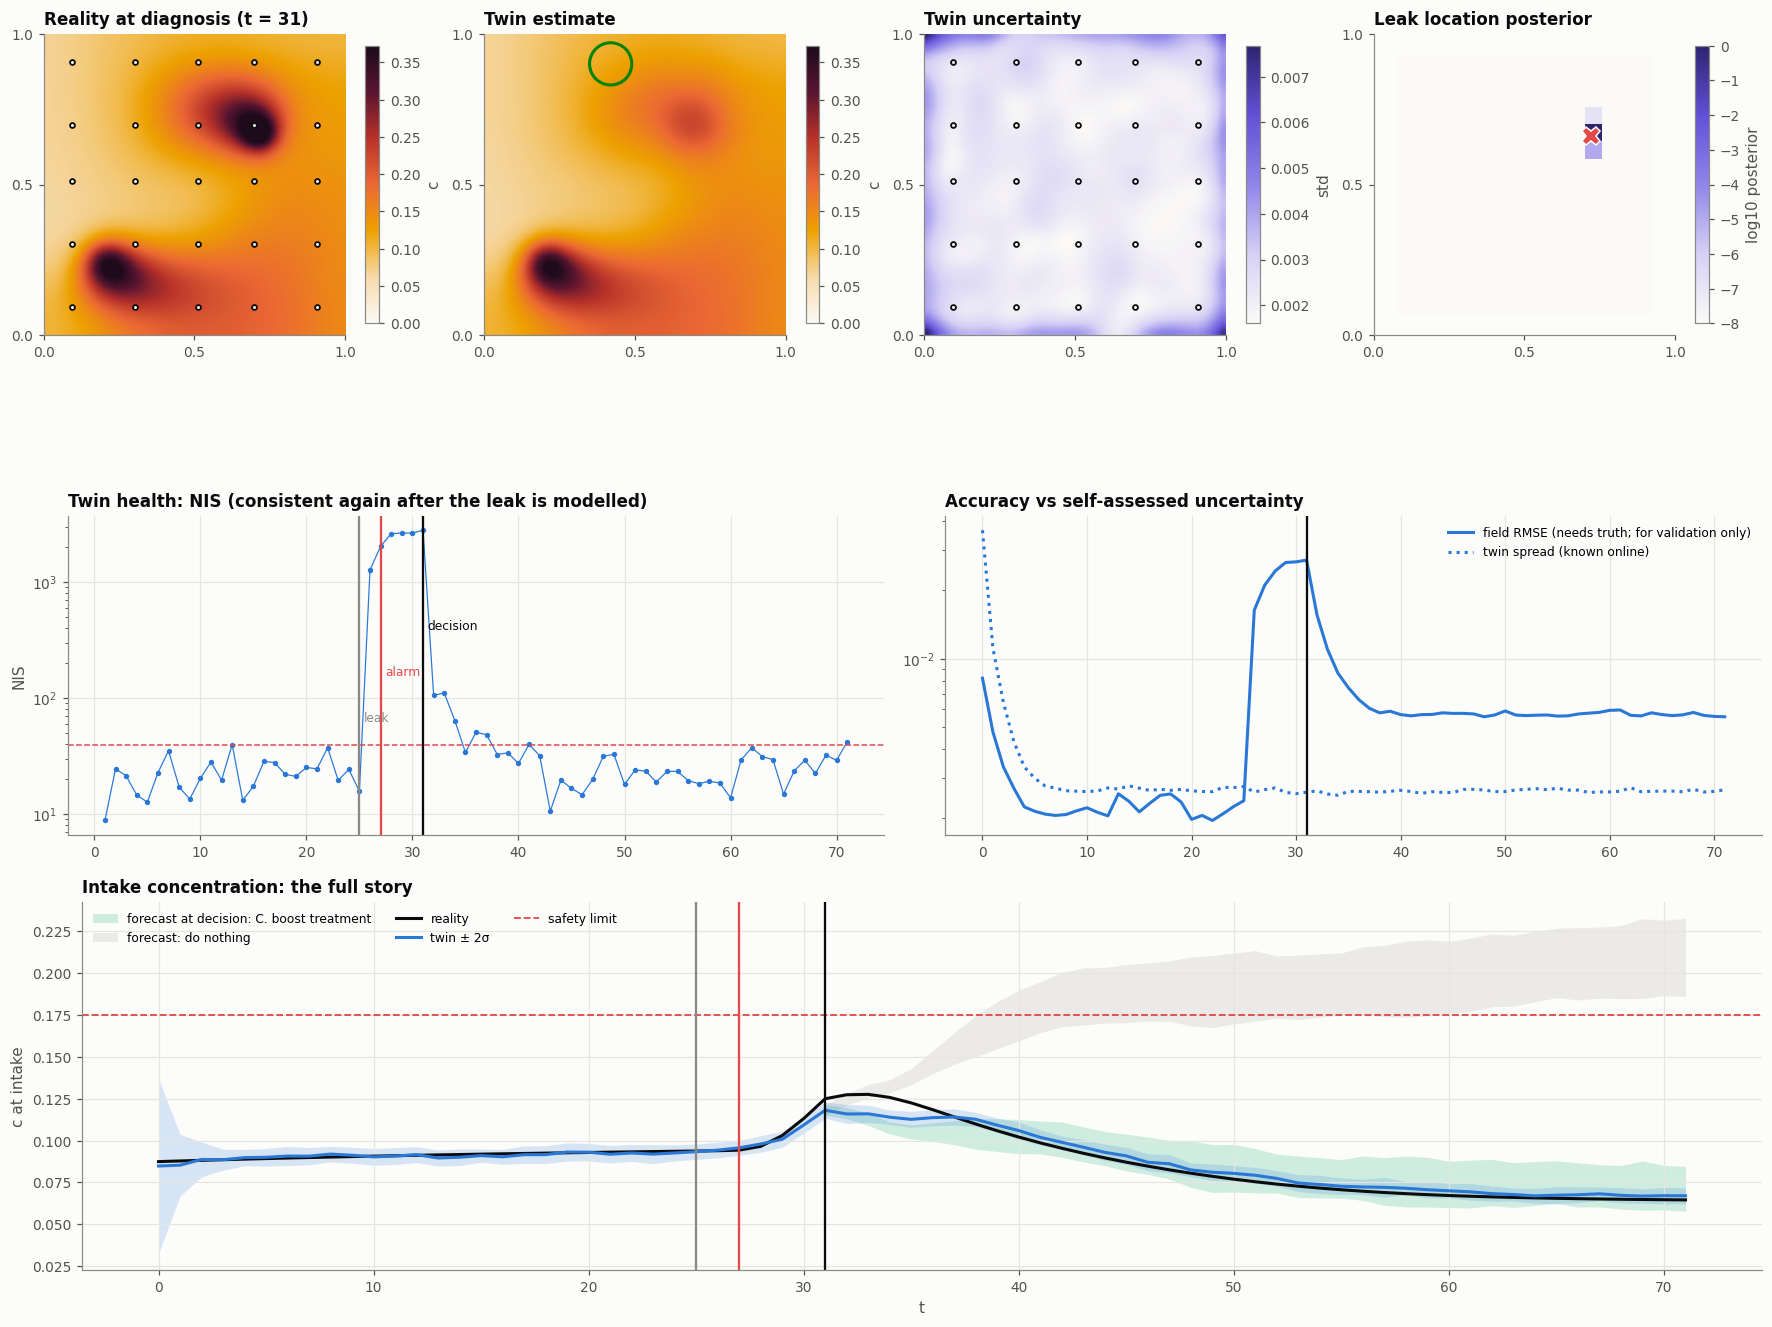

In [11]:
fig = plt.figure(figsize=(16, 13), layout="constrained")
top, mid, bot = fig.subfigures(3, 1, height_ratios=[1.25, 0.8, 0.95])
axs = top.subplots(1, 4)
vmax_c = TR.max() * 0.8
viz.field(axs[0], TR[k_d], vmin=0, vmax=vmax_c, label="c", title=f"Reality at diagnosis (t = {k_d})")
viz.sensors_2d(axs[0], sx, sy, s=10)
viz.field(axs[1], MN[k_d], vmin=0, vmax=vmax_c, label="c", title="Twin estimate")
axs[1].add_patch(plt.Circle(INTAKE_XY, INTAKE_R, fill=False, color=viz.GREEN, lw=2))
viz.field(axs[2], SD[k_d], cmap=viz.UNCERTAINTY, label="std", title="Twin uncertainty")
viz.sensors_2d(axs[2], sx, sy, s=10)
viz.field(axs[3], log_p_loc, cmap=viz.UNCERTAINTY, vmin=-8, vmax=0, label="log10 posterior", title="Leak location posterior")
axs[3].images[0].set_extent([0.0714, 0.9286, 0.0714, 0.9286]); axs[3].images[0].set_interpolation("nearest")
axs[3].set(xlim=(0, 1), ylim=(0, 1))
axs[3].plot(*LEAK_XY, "X", color=viz.RED, ms=12, mec="white")
gs_mid = mid.subplots(1, 2)
gs_bot = bot.subplots(1, 1)
ax = gs_mid[0]
ax.semilogy(T_all, NIS_all, "o-", ms=2.5, lw=0.8, color=viz.TWIN)
ax.axhline(threshold, color=viz.RED, ls="--", lw=1)
for tv, lbl, c_, yy in [(T_LEAK, "leak", viz.MUTED, 1.6), (alarm_k, "alarm", viz.RED, 4), (k_d, "decision", viz.INK, 10)]:
    ax.axvline(tv, color=c_, lw=1.5)
    ax.text(tv + 0.4, threshold * yy, lbl, fontsize=8, color=c_)
ax.set(title="Twin health: NIS (consistent again after the leak is modelled)", ylabel="NIS")
ax = gs_mid[1]
ax.semilogy(T_all, rmse, color=viz.TWIN, label="field RMSE (needs truth; for validation only)")
ax.semilogy(T_all, np.sqrt((SD**2).mean((1, 2))), color=viz.TWIN, ls=":", label="twin spread (known online)")
ax.axvline(k_d, color=viz.INK, lw=1.5)
ax.set(title="Accuracy vs self-assessed uncertainty")
ax.legend(fontsize=8)
ax = gs_bot
I_tr, I_mn = intake(TR), intake(MN)
I_sd = np.sqrt((SD[:, intake_mask] ** 2).mean(-1))
F = fc[choice]
ax.fill_between(th, *np.percentile(F, [5, 95], axis=1), color=viz.AQUA, alpha=0.2, lw=0, label=f"forecast at decision: {choice}")
ax.fill_between(th, *np.percentile(fc["A. do nothing"], [5, 95], axis=1), color=viz.MUTED, alpha=0.15, lw=0, label="forecast: do nothing")
ax.plot(T_all, I_tr, color=viz.TRUTH, lw=2, label="reality")
viz.band(ax, T_all, I_mn, I_sd, color=viz.TWIN, label="twin ± 2σ")
ax.axhline(LIMIT, color=viz.RED, ls="--", lw=1.2, label="safety limit")
for tv, c_ in [(T_LEAK, viz.MUTED), (alarm_k, viz.RED), (k_d, viz.INK)]:
    ax.axvline(tv, color=c_, lw=1.5)
ax.set(xlabel="t", ylabel="c at intake", title="Intake concentration: the full story")
ax.legend(ncol=3, fontsize=8, loc="upper left")
viz.save(fig, "10_dashboard.png")
plt.show()

**An honest caveat, visible in the middle-right panel:** after the decision the field error
(≈0.007) stays above the twin's spread (≈0.003). The twin's leak model is approximate (location
snapped to the 15×15 candidate grid, strength fixed per member), so a small bias remains that the
ensemble does not know about. NIS is back under the threshold, so the twin is *usable*, but the
next upgrade would keep estimating the leak's location and strength inside the EnKF (state
augmentation, as in 06).

In [12]:
sel = np.arange(0, len(T_all), 2)
anim = viz.animate_2d([TR[sel], MN[sel], SD[sel]], T_all[sel], ["Reality", "Twin estimate", "Twin uncertainty"],
                      cmaps=[viz.FIELD, viz.FIELD, viz.UNCERTAINTY],
                      vlims=[(0, TR.max() * 0.8), (0, TR.max() * 0.8), (0, np.percentile(SD, 99.5))],
                      sensors=(sx, sy), size=3.3, interval=140)
HTML(anim.to_jshtml())

## What you built (and where to go next)
A digital twin that **monitors** a 2D field in real time, **detects** an unmodelled event before
it reaches a critical asset, **diagnoses** its location, magnitude and onset with uncertainty,
**forecasts** the consequences of alternative actions, **recommends** one, and **verifies** it.

**Towards production:**
* replace the full solver inside the EnKF with the ROM of notebook 07 for 100-1000× speed;
* use a PINN (09) offline to re-calibrate parameters from historical data;
* swap the grid-search diagnosis for an augmented EnKF or MCMC when the parameter space grows;
* handle sensor faults: a broken probe also raises NIS. Per-sensor innovation statistics tell the two apart;
* close the loop with optimal control (MPC) instead of a fixed menu of actions.

**Exercises**
1. Move the leak next to a probe, then midway between four probes. How do detection delay and location uncertainty change?
2. Inject a sensor fault (one probe stuck at 0.3 from t = 30). Does the NIS alarm fire? How would you distinguish it from a leak?
3. Halve the number of ensemble members. Does the decision change?